# Libraries

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

In [2]:
file_path = "/content/drive/MyDrive/ICT_AIML_DATAS/DataFrame/Customer.csv"

# EDA

In [3]:
df = pd.read_csv(file_path)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.shape

(7043, 21)

In [8]:
df.value_counts().sum()

np.int64(7043)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [11]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


The dataset has 7,043 customers and 21 columns. The target `Churn` is imbalanced: about 26.5% of customers left (1,869 Yes) and 73.5% stayed (5,174 No). Accuracy alone would be misleading, so the class imbalance is handled later with SMOTE.

# Data Visualization

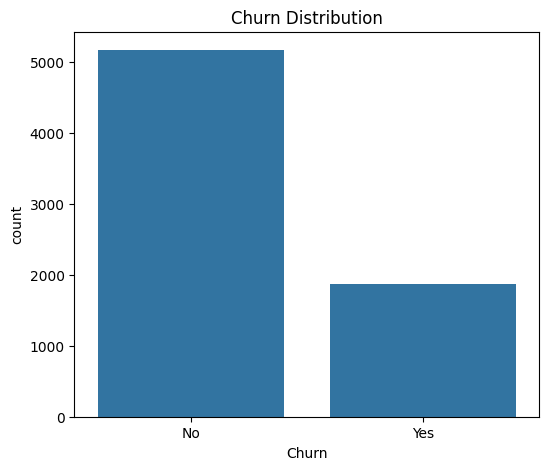

In [12]:
# Target distribution plot for checking class imbalance visually

plt.figure(figsize=(6, 5))
sns.countplot(df, x="Churn")
plt.title("Churn Distribution")
plt.show()

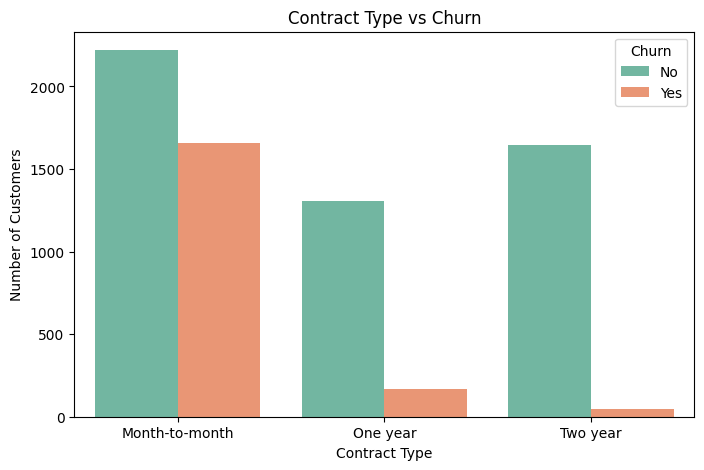

In [13]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2')
plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

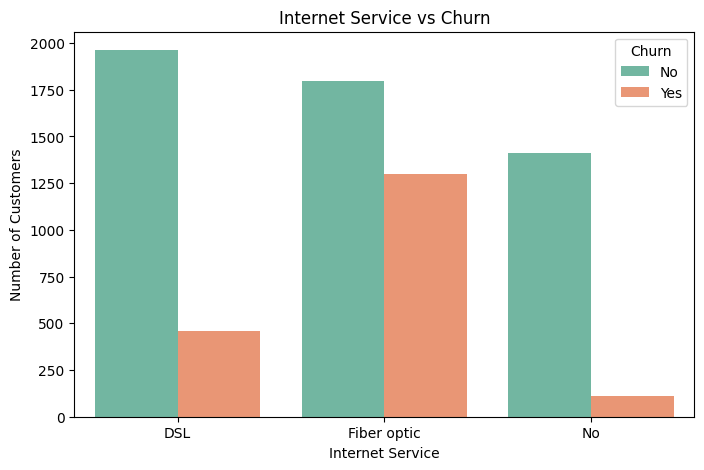

In [14]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set2')
plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

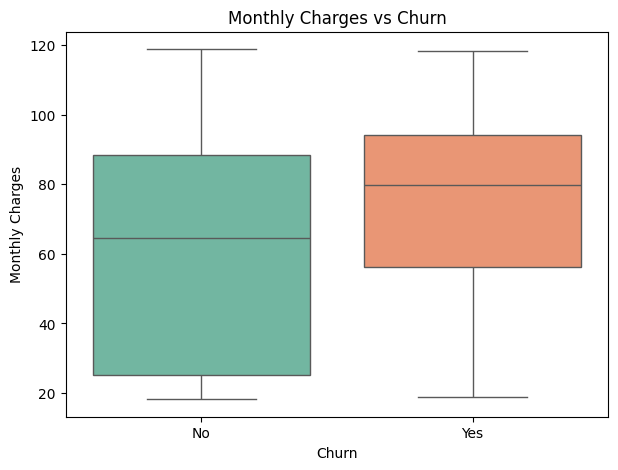

In [15]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False)
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

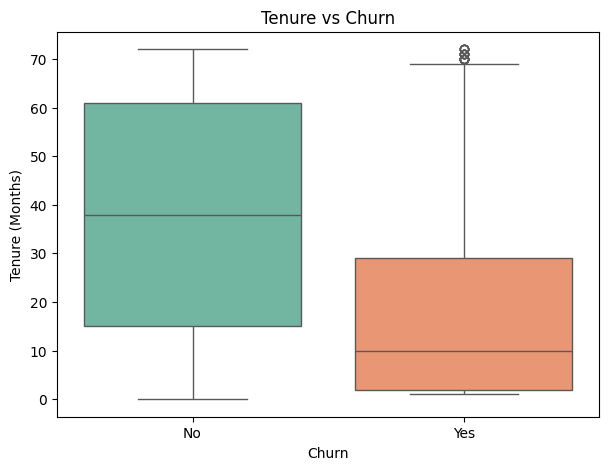

In [16]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Churn', y='tenure', hue='Churn', palette='Set2', legend=False)
plt.title("Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

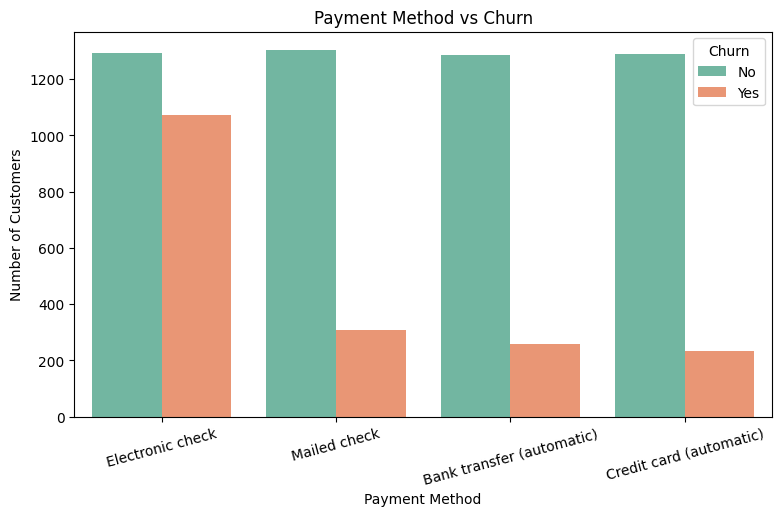

In [17]:
plt.figure(figsize=(9,5))
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette='Set2')
plt.title("Payment Method vs Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

The plots show how churn varies across the categories and numeric columns. Customers on month-to-month contracts, with fiber internet, and with low tenure appear to churn more often. Use these plots to form hypotheses, which the correlation heatmap and models test later.

# Data Cleaning

In [18]:
df = df.drop(columns = "customerID")

In [19]:
print(df['TotalCharges'].unique())
print(df['TotalCharges'].dtype)

['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']
object


In [20]:
# TotalCharges is stored as object because some values contain blank spaces.
df['TotalCharges'].str.strip().eq('').sum()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

In [21]:
print(df['TotalCharges'].dtype)

float64


In [22]:
df.isnull().sum()/ len(df)*100

,0
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000
OnlineBackup,0.000000


In [23]:
df.dropna(subset=['TotalCharges'], inplace=True)

In [24]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [25]:
cat_cols_before_split = df.select_dtypes(exclude="number")

for col in cat_cols_before_split:
  print(f"{col} ---> {df[col].unique()}")
  print(" ")

gender ---> ['Female' 'Male']
 
Partner ---> ['Yes' 'No']
 
Dependents ---> ['No' 'Yes']
 
PhoneService ---> ['No' 'Yes']
 
MultipleLines ---> ['No phone service' 'No' 'Yes']
 
InternetService ---> ['DSL' 'Fiber optic' 'No']
 
OnlineSecurity ---> ['No' 'Yes' 'No internet service']
 
OnlineBackup ---> ['Yes' 'No' 'No internet service']
 
DeviceProtection ---> ['No' 'Yes' 'No internet service']
 
TechSupport ---> ['No' 'Yes' 'No internet service']
 
StreamingTV ---> ['No' 'Yes' 'No internet service']
 
StreamingMovies ---> ['No' 'Yes' 'No internet service']
 
Contract ---> ['Month-to-month' 'One year' 'Two year']
 
PaperlessBilling ---> ['Yes' 'No']
 
PaymentMethod ---> ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
 
Churn ---> ['No' 'Yes']
 


In [26]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [27]:
# Outlier check on numeric columns, using training data only
num_check = ['tenure', 'MonthlyCharges', 'TotalCharges']

Q1 = X_train[num_check].quantile(0.25)
Q3 = X_train[num_check].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

is_outlier = (X_train[num_check] < lower) | (X_train[num_check] > upper)
print("Outliers per column:")
print(is_outlier.sum())
print("Share of rows with at least one outlier:", round(is_outlier.any(axis=1).mean(), 4))

Outliers per column:
tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64
Share of rows with at least one outlier: 0.0


**Outlier decision:** The IQR check on the training data found 0 outliers in tenure, MonthlyCharges, and TotalCharges. No rows fall outside the 1.5 × IQR bounds, so I did not remove or cap any values. Scaling is still applied to the numeric columns so they share a common scale.

In [28]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

`TotalCharges` is stored as text because 11 rows contain a blank space instead of a number. These 11 rows are 0.16% of the data and have tenure 0, so they are new customers with no charges yet. I convert the column to numeric and drop these rows, since imputing them would add little information. `customerID` is an identifier, so it is removed because it has no predictive value. and no outliers present

# Scaling

In [29]:
scaler = StandardScaler()

# Scale the actual numeric data from X_train and X_test using the num_cols index
X_train_num_scaled = scaler.fit_transform(X_train[num_cols])
X_test_num_scaled = scaler.transform(X_test[num_cols])

In [30]:
X_train_num_scaled = pd.DataFrame(X_train_num_scaled, columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(X_test_num_scaled, columns=num_cols, index=X_test.index)


X_train_cat = pd.DataFrame(X_train[cat_cols], columns=cat_cols, index=X_train.index)
X_test_cat = pd.DataFrame(X_test[cat_cols], columns=cat_cols, index=X_test.index)

Numeric columns are scaled with StandardScaler. It is fit on the training data only and then applied to the test data, so no test information leaks into training. Scaling matters most for KNN, which depends on distances.

# Encoding

In [31]:
for col in cat_cols:
  print(f"{col} ---->  {X_train_cat[col].unique()}")
  print(" ")

gender ---->  ['Male' 'Female']
 
Partner ---->  ['Yes' 'No']
 
Dependents ---->  ['Yes' 'No']
 
PhoneService ---->  ['Yes' 'No']
 
MultipleLines ---->  ['Yes' 'No phone service' 'No']
 
InternetService ---->  ['Fiber optic' 'DSL' 'No']
 
OnlineSecurity ---->  ['Yes' 'No' 'No internet service']
 
OnlineBackup ---->  ['Yes' 'No' 'No internet service']
 
DeviceProtection ---->  ['Yes' 'No' 'No internet service']
 
TechSupport ---->  ['Yes' 'No' 'No internet service']
 
StreamingTV ---->  ['No' 'Yes' 'No internet service']
 
StreamingMovies ---->  ['No' 'Yes' 'No internet service']
 
Contract ---->  ['Two year' 'Month-to-month' 'One year']
 
PaperlessBilling ---->  ['No' 'Yes']
 
PaymentMethod ---->  ['Credit card (automatic)' 'Electronic check' 'Bank transfer (automatic)'
 'Mailed check']
 


In [32]:
ord_enc = OrdinalEncoder(
    categories=[['Month-to-month', 'One year', 'Two year']]
)

ord_train = pd.DataFrame(
    ord_enc.fit_transform(X_train_cat[['Contract']]),
    columns=['Contract'],
    index=X_train.index
)

ord_test = pd.DataFrame(
    ord_enc.transform(X_test_cat[['Contract']]),
    columns=['Contract'],
    index=X_test.index
)

In [33]:
oh_cols = [
    "gender", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "PaperlessBilling",
    "PaymentMethod"
]

oh_enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

oh_train = pd.DataFrame(
    oh_enc.fit_transform(X_train_cat[oh_cols]),
    columns=oh_enc.get_feature_names_out(oh_cols),
    index=X_train.index
)

oh_test = pd.DataFrame(
    oh_enc.transform(X_test_cat[oh_cols]),
    columns=oh_enc.get_feature_names_out(oh_cols),
    index=X_test.index
)

In [34]:
X_train_final = pd.concat([X_train_num_scaled, ord_train, oh_train], axis=1)
X_test_final = pd.concat([X_test_num_scaled, ord_test, oh_test], axis=1)

print(X_train_final.shape, X_test_final.shape)
X_train_final.head()


(5625, 43) (1407, 43)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Contract,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1413,-0.439319,1.321816,0.981556,1.659900,2.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
7003,-0.439319,-0.267410,-0.971546,-0.562252,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3355,-0.439319,1.444064,0.837066,1.756104,2.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4494,-0.439319,-1.204646,0.641092,-0.908326,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
3541,-0.439319,0.669826,-0.808787,-0.101561,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [35]:
print(X_train_final.isnull().sum().sum())
print(X_test_final.isnull().sum().sum())

0
0


In [36]:
y_train = y_train.map({'No': 0, 'Yes': 1})
y_test = y_test.map({'No': 0, 'Yes': 1})

In [37]:
print(y_test.value_counts())
print(y_test.isnull().sum())

Churn
0    1033
1     374
Name: count, dtype: int64
0


`Contract` has a natural order (month-to-month < one year < two year), so it uses an ordinal encoder. The other 14 categorical columns have no order, so they use one-hot encoding. Encoders are fit on training data only. The result is 43 features for both sets (5,625 training and 1,407 test rows), with no missing values after encoding.

# Class Imbalance

In [38]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_final, y_train)

print(y_train_smote.value_counts())

Churn
0    4130
1    4130
Name: count, dtype: int64


# Feature Selection

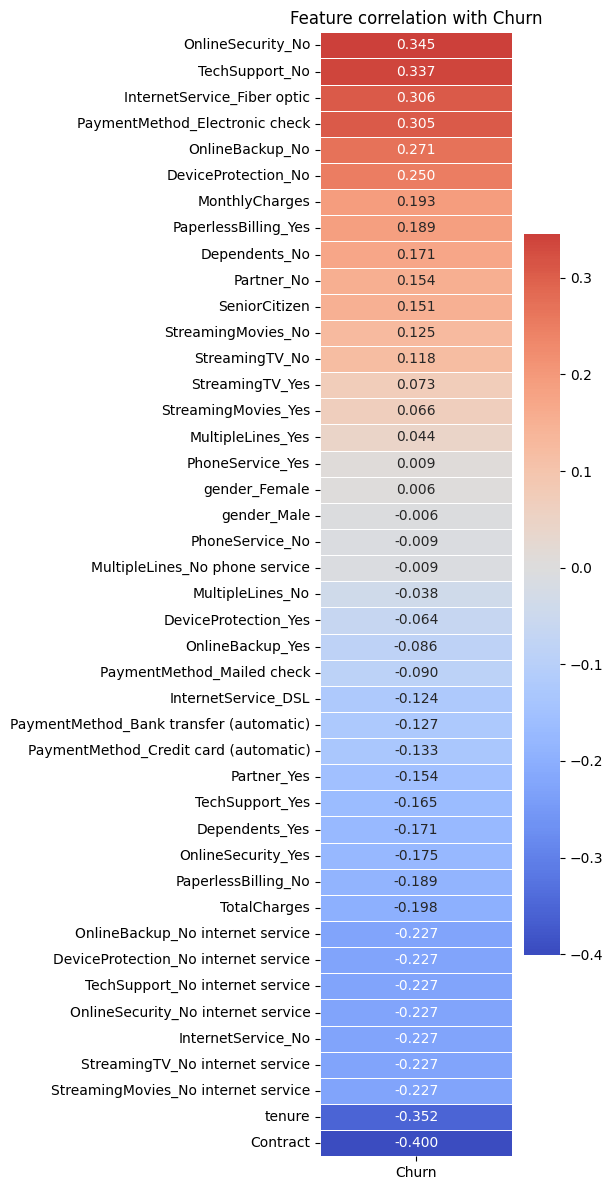

In [39]:
corr = X_train_final.corrwith(y_train).sort_values(ascending=False).to_frame("Churn")

plt.figure(figsize=(6, 12))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    center=0
)
plt.title("Feature correlation with Churn")
plt.tight_layout()
plt.show()

In [40]:
features_selected = ['Contract', 'tenure','OnlineBackup_No']
X_train_selected = X_train_smote[features_selected]
X_test_selected = X_test_final[features_selected]

**Feature selection reason:** I selected Contract, tenure, and OnlineBackup_No. are among the strongest predictors in the correlation heatmap

In [41]:
# Selected features from the scaled training data, before SMOTE
X_tr_sel = X_train_final[features_selected]

# Split the training data into a smaller training part and a validation part
X_sub, X_val, y_sub, y_val = train_test_split(
    X_tr_sel, y_train, test_size=0.2, stratify=y_train, random_state=42)

# Apply SMOTE to the smaller training part only
X_sub_sm, y_sub_sm = SMOTE(random_state=42).fit_resample(X_sub, y_sub)

# Try odd values of k and record validation F1 for the churn class
val_f1 = {}
for k in range(1, 31, 2):
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_sub_sm, y_sub_sm)
    val_f1[k] = f1_score(y_val, m.predict(X_val))

for k, f in val_f1.items():
    print(f"k={k:2d}  validation F1 = {f:.4f}")

best_k = max(val_f1, key=val_f1.get)
print("Best k:", best_k)

k= 1  validation F1 = 0.3563
k= 3  validation F1 = 0.3669
k= 5  validation F1 = 0.3858
k= 7  validation F1 = 0.3946
k= 9  validation F1 = 0.4218
k=11  validation F1 = 0.4401
k=13  validation F1 = 0.4425
k=15  validation F1 = 0.4270
k=17  validation F1 = 0.4241
k=19  validation F1 = 0.4691
k=21  validation F1 = 0.4780
k=23  validation F1 = 0.4920
k=25  validation F1 = 0.4675
k=27  validation F1 = 0.4901
k=29  validation F1 = 0.4993
Best k: 29


**Choosing k:** I tested odd values of k from 1 to 29 using validation F1-score for the churn class. F1 increased steadily and peaked at k = 29 (0.4993). I used F1 rather than accuracy because churners are the minority class, and accuracy alone would hide missed churners.

# Logistic Regression

In [42]:
log_reg = LogisticRegression()
knn = KNeighborsClassifier(n_neighbors = 3)

In [43]:
log_reg.fit(X_train_selected, y_train_smote)
knn.fit(X_train_selected, y_train_smote)

KNeighborsClassifier(n_neighbors=3)

In [44]:
#Predict the target labels for the training set using the trained Logistic Regression model
lr_train_pred = log_reg.predict(X_train_selected)
# Predict the target labels for the test set using the trained Logistic Regression model
lr_test_pred = log_reg.predict(X_test_selected)

In [45]:
#Predict the target labels for the training set using the trained (KNN)
knn_train_pred = knn.predict(X_train_selected)
# Predict the target labels for the test set using the trained (KNN)
knn_test_pred = knn.predict(X_test_selected)

Logistic Regression is trained on the SMOTE-balanced data using the three selected features. Test accuracy is 0.6667 and training accuracy is 0.7378, a small gap that suggests no overfitting. Its strength is recall: at the default threshold of 0.5 it catches 84% of churners.

# Accuracy Score

In [46]:
#Accuracy Score
# Calculate accuracy on train set
lr_train_acc = accuracy_score(y_train_smote, lr_train_pred)

# Calculate accuracy on test set
lr_test_acc = accuracy_score(y_test, lr_test_pred)

In [47]:
# Print the training accuracy of the logistic Regression model
print(f" Logistic Regression Train Accuracy : {lr_train_acc:.4f}")

# Print the testing accuracy of the Logistic Regression Model
print(f" Logistic Regression Test Accuracy : {lr_test_acc:.4f}")

 Logistic Regression Train Accuracy : 0.7378
 Logistic Regression Test Accuracy : 0.6667


Accuracy is the share of correct predictions. The training score uses the balanced SMOTE data, so it is not directly comparable to the test score. Accuracy is a basic check only; the main decisions rest on recall and F1, because missing a churner is the costly error.

# KNN

In [48]:
#KNN Score
# Calculate KNN on train set
knn_train_acc = accuracy_score(y_train_smote, knn_train_pred)

# Calculate KNN on test set
knn_test_acc = accuracy_score(y_test, knn_test_pred)

In [49]:
# Print the training accuracy of KNN
print(f" KNN Train Accuracy : {knn_train_acc:.4f}")

# Print the testing accuracy of KNN
print(f" KNN Test Accuracy : {knn_test_acc:.4f}")

 KNN Train Accuracy : 0.7952
 KNN Test Accuracy : 0.7321


KNN classifies a customer by the majority class of its nearest neighbours. The first run used k = 3, which overfit (training accuracy about 0.80, test about 0.73). I chose k on a validation split using F1-score, which selected k = 29. With k = 29, test accuracy is 0.7029 and training accuracy is 0.7508, a gap of about 0.05, which indicates better generalization. Accuracy went down slightly, but the model is more reliable.

# Confusion Matrix

In [50]:
# Calculate the confusion matrix for the Logistic Regression model on the test set
lr_cm = confusion_matrix(y_test, lr_test_pred)

#Print the confusion matrix to visualize model performance
print("Confusion Matrix: ")
print(lr_cm)


Confusion Matrix: 
[[622 411]
 [ 58 316]]


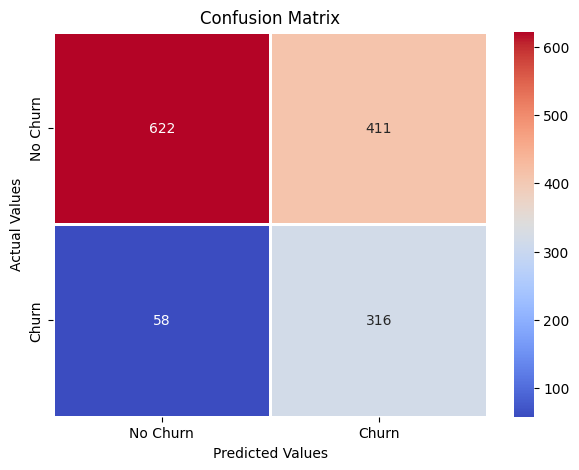

In [51]:
#HEAT MAP
plt.figure(figsize=(7,5))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='coolwarm',
    linewidths=1,
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

# Classification Report

In [52]:
#Generates a classification report for the Logistic Regression model on the test set

log_cr = classification_report(y_test, lr_test_pred)

#Print the classification report to evaluate model performance in detail
print("Classification Report:")
print(log_cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.60      0.73      1033
           1       0.43      0.84      0.57       374

    accuracy                           0.67      1407
   macro avg       0.67      0.72      0.65      1407
weighted avg       0.79      0.67      0.69      1407



In [53]:
#Generates a classification report for the KNN on the test set
KNN_cr = classification_report(y_test, knn_test_pred)
print("Classification Report:")
print(KNN_cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.84      0.82      1033
           1       0.50      0.43      0.46       374

    accuracy                           0.73      1407
   macro avg       0.65      0.63      0.64      1407
weighted avg       0.72      0.73      0.73      1407



In [54]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_selected, y_train_smote)

knn_train_pred = knn.predict(X_train_selected)
knn_test_pred = knn.predict(X_test_selected)

knn_train_acc = accuracy_score(y_train_smote, knn_train_pred)
knn_test_acc = accuracy_score(y_test, knn_test_pred)
print(f"KNN (k={best_k}) Train Accuracy : {knn_train_acc:.4f}")
print(f"KNN (k={best_k}) Test Accuracy  : {knn_test_acc:.4f}")

# Rerun the KNN classification report so it uses the new model
KNN_cr = classification_report(y_test, knn_test_pred)
print("Classification Report (KNN):")
print(KNN_cr)

KNN (k=29) Train Accuracy : 0.7508
KNN (k=29) Test Accuracy  : 0.7029
Classification Report (KNN):
              precision    recall  f1-score   support

           0       0.81      0.78      0.79      1033
           1       0.45      0.49      0.47       374

    accuracy                           0.70      1407
   macro avg       0.63      0.64      0.63      1407
weighted avg       0.71      0.70      0.71      1407



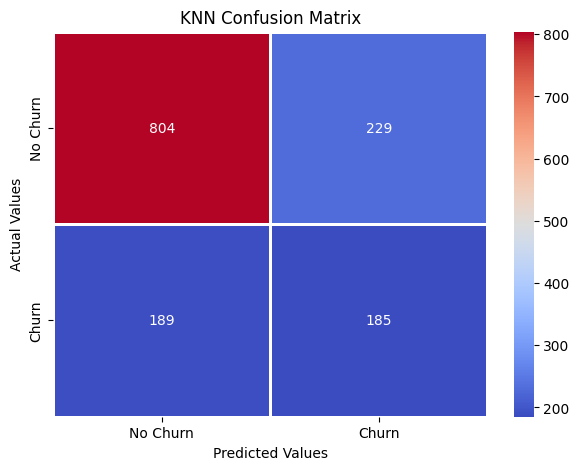

In [55]:
#KNN confusion matrix heatmap
knn_cm = confusion_matrix(y_test, knn_test_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='coolwarm',
    linewidths=1,
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

In [56]:
#False positive and false negative explanation
thresholds = [0.3, 0.5, 0.7]

for name, model in [("Logistic Regression", log_reg), ("KNN", knn)]:
    proba = model.predict_proba(X_test_selected)[:, 1]
    print(f"\n{name}")
    print(f"{'Threshold':>10}{'TN':>6}{'FP':>6}{'FN':>6}{'TP':>6}{'Prec':>8}{'Recall':>8}{'F1':>8}")
    for t in thresholds:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        print(f"{t:>10.1f}{tn:>6}{fp:>6}{fn:>6}{tp:>6}"
              f"{precision_score(y_test, pred):>8.3f}"
              f"{recall_score(y_test, pred):>8.3f}"
              f"{f1_score(y_test, pred):>8.3f}")


Logistic Regression
 Threshold    TN    FP    FN    TP    Prec  Recall      F1
       0.3   502   531    36   338   0.389   0.904   0.544
       0.5   622   411    58   316   0.435   0.845   0.574
       0.7   833   200   162   212   0.515   0.567   0.539

KNN
 Threshold    TN    FP    FN    TP    Prec  Recall      F1
       0.3   567   466    78   296   0.388   0.791   0.521
       0.5   804   229   189   185   0.447   0.495   0.470
       0.7  1004    29   349    25   0.463   0.067   0.117


Precision, recall, and F1 are reported for each class. For logistic regression, churn precision is 0.43 and recall is 0.84, giving an F1 of 0.57.

# Decision Tree

In [57]:
dt = DecisionTreeClassifier(random_state=42)   # build
dt.fit(X_train_selected, y_train_smote)        # train
y_pred_dt = dt.predict(X_test_selected)        # predict

dt_accuracy = accuracy_score(y_test, y_pred_dt)  # evaluate
print(f"Decision Tree Test Accuracy: {dt_accuracy:.4f}")

Decision Tree Test Accuracy: 0.7392


In [58]:
# Evaluate with precision, recall and F1-score
print(f"Decision Tree Precision: {precision_score(y_test, y_pred_dt):.4f}")
print(f"Decision Tree Recall   : {recall_score(y_test, y_pred_dt):.4f}")
print(f"Decision Tree F1-score : {f1_score(y_test, y_pred_dt):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Precision: 0.5103
Decision Tree Recall   : 0.4626
Decision Tree F1-score : 0.4853

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.84      0.83      1033
           1       0.51      0.46      0.49       374

    accuracy                           0.74      1407
   macro avg       0.66      0.65      0.66      1407
weighted avg       0.73      0.74      0.73      1407



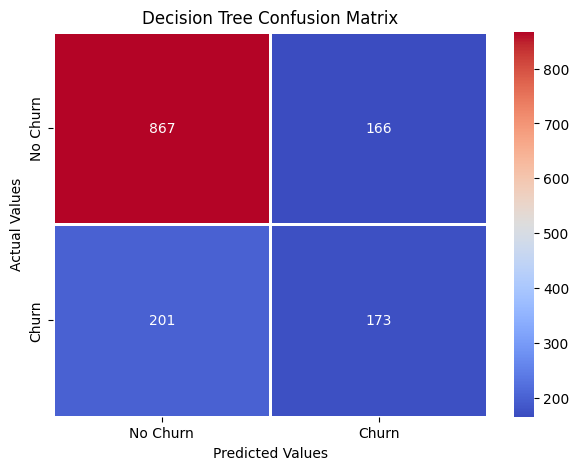

In [59]:
# Confusion matrix heatmap
dt_cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))
sns.heatmap(dt_cm, annot=True, fmt='d', cmap='coolwarm', linewidths=1,
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

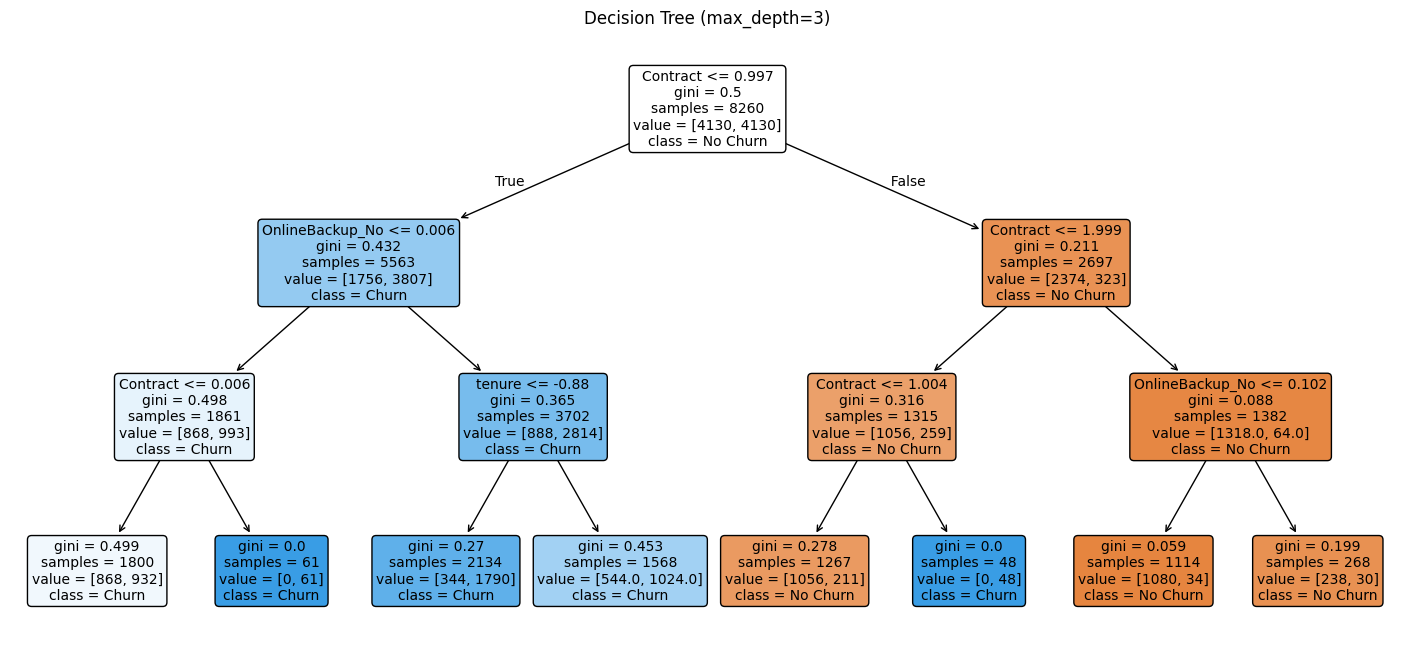

In [64]:
# Visualize the tree (max_depth=3 so it stays readable)
dt3 = DecisionTreeClassifier(max_depth=3, random_state=42)
dt3.fit(X_train_selected, y_train_smote)

plt.figure(figsize=(18, 8))
plot_tree(dt3, feature_names=features_selected,
          class_names=['No Churn', 'Churn'],
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree (max_depth=3)")
plt.show()

In [63]:
# Try max_depth = 3, 5, 10 and None on the test set and record the results
results = []
for d in [3, 5, 10, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train_selected, y_train_smote)
    p = m.predict(X_test_selected)
    results.append({
        'max_depth': str(d),
        'Train Acc': round(accuracy_score(y_train_smote, m.predict(X_train_selected)), 4),
        'Test Acc': round(accuracy_score(y_test, p), 4),
        'Precision': round(precision_score(y_test, p), 4),
        'Recall': round(recall_score(y_test, p), 4),
        'F1': round(f1_score(y_test, p), 4),
        'Depth': m.get_depth(),
        'Leaves': m.get_n_leaves(),
    })

depth_df = pd.DataFrame(results)
print(depth_df.to_string(index=False))

max_depth  Train Acc  Test Acc  Precision  Recall     F1  Depth  Leaves
        3     0.7541    0.6361     0.4127  0.8717 0.5601      3       8
        5     0.7627    0.6944     0.4556  0.7674 0.5717      5      24
       10     0.7858    0.6994     0.4580  0.7139 0.5580     10     149
     None     0.8421    0.7392     0.5103  0.4626 0.4853     37     486


In [65]:
# Choose the best depth on the validation split (same split used for k)
val_scores = {}
for d in [3, 5, 10, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_sub_sm, y_sub_sm)
    val_scores[str(d)] = f1_score(y_val, m.predict(X_val))

for d, f in val_scores.items():
    print(f"max_depth={d:>4}  validation F1 = {f:.4f}")

best_depth_str = max(val_scores, key=val_scores.get)
best_depth = None if best_depth_str == 'None' else int(best_depth_str)
print("Best max_depth:", best_depth)

max_depth=   3  validation F1 = 0.5582
max_depth=   5  validation F1 = 0.5583
max_depth=  10  validation F1 = 0.5477
max_depth=None  validation F1 = 0.5251
Best max_depth: 5


In [66]:
# Task 3: Compare KNN, Logistic Regression and Decision Tree in one table
dt_best = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_best.fit(X_train_selected, y_train_smote)
dt_best_pred = dt_best.predict(X_test_selected)

def model_row(name, pred):
    return {
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, pred), 4),
        'Precision': round(precision_score(y_test, pred), 4),
        'Recall': round(recall_score(y_test, pred), 4),
        'F1': round(f1_score(y_test, pred), 4),
    }

comparison = pd.DataFrame([
    model_row(f"KNN (k={best_k})", knn_test_pred),
    model_row("Logistic Regression", lr_test_pred),
    model_row(f"Decision Tree (max_depth={best_depth})", dt_best_pred),
])
print(comparison.to_string(index=False))

                      Model  Accuracy  Precision  Recall     F1
                 KNN (k=29)    0.7029     0.4469  0.4947 0.4695
        Logistic Regression    0.6667     0.4347  0.8449 0.5740
Decision Tree (max_depth=5)    0.6944     0.4556  0.7674 0.5717
